# A hard solve from scratch: does the optimizer decide success?

In notebook 03 SOAP halved the error of Kolmogorov fine-tuning, while on Darcy every optimizer reached the same discretization floor. Is the optimizer what matters on *hard* single-instance problems? Here a **randomly initialized FNO** solves one Kolmogorov instance from the PDE loss alone: no data, no pretrained operator.

- **Problem:** Kolmogorov flow at Re = 100 over **T = 1** (8× the horizon of notebook 03), on a 64² × 65 grid, Crank–Nicolson time residual, initial-condition weight 5.
- **Model and training:** FNO width 32, modes 8×8×8, the same random initialization for every optimizer, 1500 steps with cosine decay.
- **Learning rates:** fixed in advance, not swept: Adam, Muon and Muon-spec 1e-3, SOAP 3e-3 (the Kolmogorov defaults used throughout).
- **Floor:** the error of the exact minimizer of the discrete loss (L-BFGS on the grid values), so every curve reads as distance to what the loss allows.

Reference: Li, Zheng et al., *Physics-Informed Neural Operator for Learning Partial Differential Equations*, arXiv:2111.03794. This notebook reads the saved results in `../results/hard_solve`.

In [1]:
import os, sys, json
sys.path.insert(0, os.path.abspath(".."))          # repo root
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
import analysis as an, pino_bench as pb, experiments as ex
pd.set_option("display.width", 200)

### Reproducing
`python exp5_hard_case.py` (about 13 hours on 2 CPU cores; checkpoints every 10 minutes and resumes) writes to `../runs/exp5_hard/`. Configuration:

In [2]:
import exp5_hard_case as e5
dict(Re=e5.RE, T=e5.T, grid=(e5.N, e5.N, e5.NT), steps=e5.STEPS, ic_weight=e5.W_IC, lrs=e5.OPTS, model=e5.MODEL, instances=e5.SEEDS)

{'Re': 100.0,
 'T': 1.0,
 'grid': (64, 64, 65),
 'steps': 1500,
 'ic_weight': 5.0,
 'lrs': {'adam': 0.001, 'muon': 0.001, 'muon_spectral': 0.001, 'soap': 0.003},
 'model': {'modes': (8, 8, 8),
  'width': 32,
  'layers': 4,
  'pad_frac': 0.25,
  'pad_mode': 'points'},
 'instances': [1, 2]}

## Results

In [3]:
an.hard_table()

lr  floor (%)  final (%)  first step < 8%  minutes
instance optimizer                                                       
1        Adam       0.001       1.52       7.64             1200     83.6
         Muon       0.001       1.52       6.12              900     84.2
         SOAP       0.003       1.52       3.14              480     90.4
         Muon-spec  0.001       1.52      39.49             <NA>    146.0
2        Adam       0.001       0.78       6.50             1020     79.8
         Muon       0.001       0.78       2.09              630     81.2
         SOAP       0.003       0.78       0.66              390     92.3
         Muon-spec  0.001       0.78      39.23             <NA>    145.3

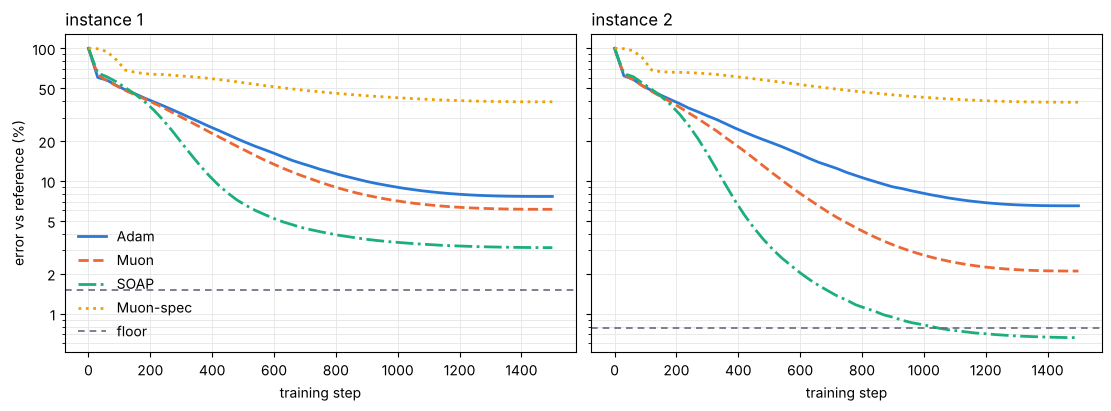

In [4]:
fig = an.plot_hard(); plt.show()

## Observations

- **SOAP is best by a wide margin.** It ends at 3.14% and 0.66% (floors 1.52% and 0.78%), against Adam's 7.64% and 6.50%: 2–10× lower. It crosses 8% error after 480 and 390 steps, about 2.5× sooner than Adam.
- **SOAP ends slightly below the floor on instance 2.** As in notebook 06, the floor is the error of the exact discrete minimizer, not a lower bound.
- **Muon is a clear second** (6.12% and 2.09%), consistent with every other comparison here.
- **Muon-spec barely trains at 1e-3** (39%). Its curve is smooth but slow: orthogonalized updates have a fixed size per step, so at this rate the spectral weights hardly move. This says it needs a different learning rate, not that it fails.
- **Together with notebook 03:** on the hard, chaotic solves (Kolmogorov fine-tuning and this one) curvature-aware SOAP is worth its extra cost per step (≈10% here); on the easy, well-conditioned one (Darcy fine-tuning) no optimizer can beat the grid.
- **Caveats:** two instances, one initialization, learning rates not tuned for this problem.